In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.shape

(1338, 7)

In [5]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
df = df.drop_duplicates()

df.duplicated().sum()


np.int64(0)

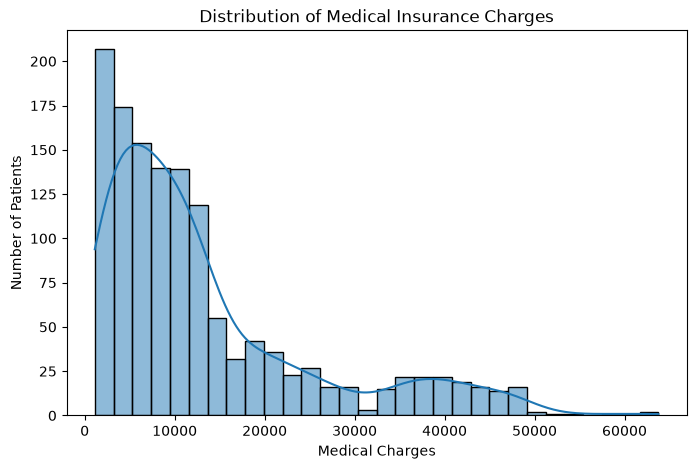

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(df["charges"], bins=30, kde=True)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Medical Charges")
plt.ylabel("Number of Patients")

plt.show()

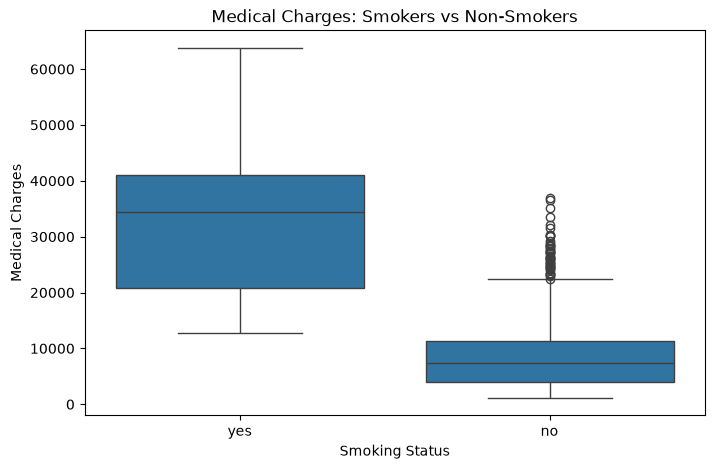

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(x="smoker", y="charges", data=df)

plt.title("Medical Charges: Smokers vs Non-Smokers")
plt.xlabel("Smoking Status")
plt.ylabel("Medical Charges")

plt.show()

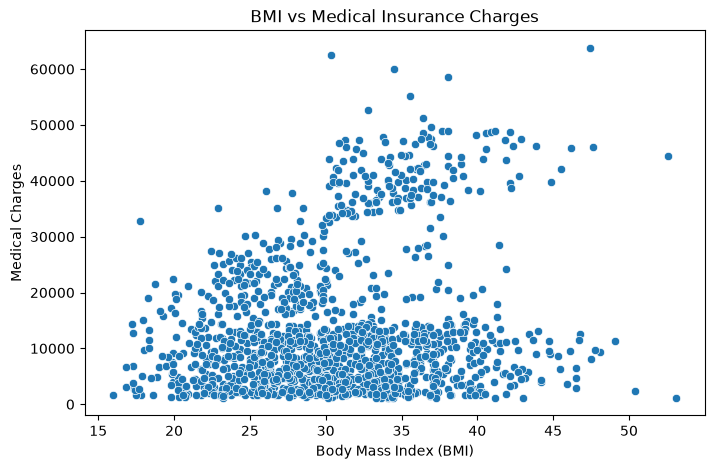

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x="bmi", y="charges", data=df)

plt.title("BMI vs Medical Insurance Charges")
plt.xlabel("Body Mass Index (BMI)")
plt.ylabel("Medical Charges")

plt.show()

In [11]:
df.groupby("smoker")["charges"].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

In [12]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [13]:
X = df.drop("charges", axis=1)

y = df["charges"]

X = pd.get_dummies(X, columns=["sex", "smoker", "region"], dtype=int)

X.head()

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,1,0,0,1,0,0,0,1
1,18,33.770,1,0,1,1,0,0,0,1,0
2,28,33.000,3,0,1,1,0,0,0,1,0
3,33,22.705,0,0,1,1,0,0,1,0,0
4,32,28.880,0,0,1,1,0,0,1,0,0


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1069, 11)
Testing data: (268, 11)


In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [16]:
y_pred = model.predict(X_test)

print("First 10 actual charges:")
print(y_test.head(10).values)

print("\nFirst 10 predicted charges:")
print(y_pred[:10])

First 10 actual charges:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051   9304.7019
 38511.6283   2150.469    7345.7266  10264.4421 ]

First 10 predicted charges:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706 13149.72235307 30446.76067941  1453.28881259
 10633.01840233 11318.94379361]


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared Score (R2):", r2)

Mean Absolute Error (MAE): 4177.045561036322
Root Mean Squared Error (RMSE): 5956.342894363589
R-squared Score (R2): 0.8069287081198011


In [18]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest model training completed!")

Random Forest model training completed!


In [19]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 2558.254771226865
Random Forest RMSE: 4642.16355496707
Random Forest R2: 0.882726686689128


In [20]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
5,smoker_no,0.438462
1,bmi,0.212045
6,smoker_yes,0.162315
0,age,0.135756
2,children,0.022760
8,region_northwest,0.005892
9,region_southeast,0.005354
7,region_northeast,0.004787
3,sex_female,0.004486
4,sex_male,0.004462


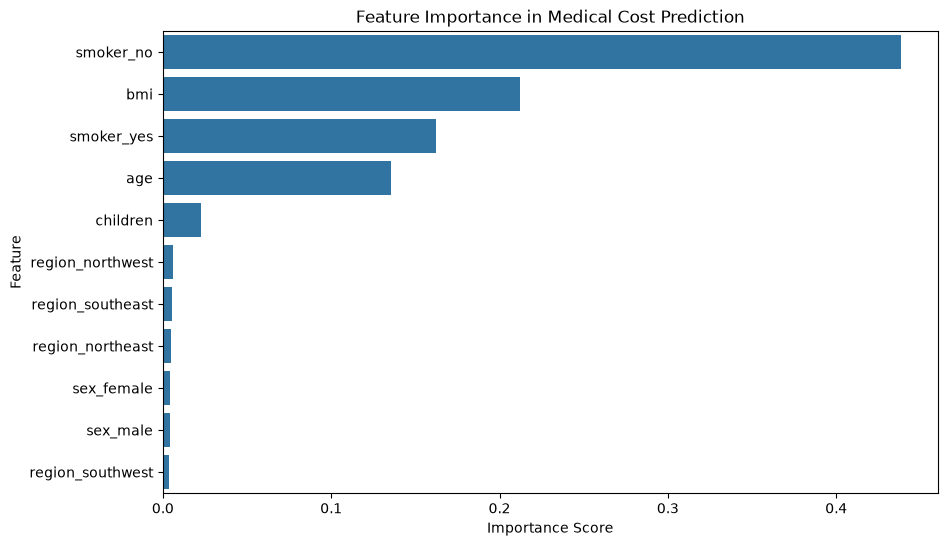

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=importance
)

plt.title("Feature Importance in Medical Cost Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

In [22]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(rf_model, "../models/medical_cost_model.pkl")

joblib.dump(X_train.columns.tolist(), "../models/model_columns.pkl")

print("Model and feature columns saved successfully!")

Model and feature columns saved successfully!
